# 03 – Correlation Analysis

## Context
This notebook is part of a project on the effect of diversification in a portfolio.
After analysing each asset separately, it studies how the assets move together to identify what really diversifies the portfolio.

## Questions
- Which assets are redundant?
- Which assets bring real diversification?
- Are these relationships stable over time?
- Do they hold during market stress?

## Contents
1. Daily returns
2. Daily correlation matrix
3. Weekly correlation matrix
4. Daily vs weekly correlation
5. Rolling correlation
6. Correlation during market stress
7. Conclusion

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

## Data loading
The dataset was cleaned in notebook 01, so it is only loaded here.
Asset names are retrieved from Yahoo Finance to make the results easier to read.

In [2]:
df = pd.read_csv("../Data/Processed/dataset_clean.csv", index_col='Date', parse_dates=True)

name_by_ticker = {}
for ticker in df.columns:
    info = yf.Ticker(ticker).info
    name_by_ticker[ticker] = info.get("shortName", ticker)


n_rows, n_assets = df.shape
start, end = df.index.min(), df.index.max()
n_years = (end - start).days / 365.25

print("=== Assets ===")
for ticker, name in name_by_ticker.items():
    print(f"  {ticker:<10} {name}")

print("\n=== Dataset overview ===")
print(f"{'Number of assets':<22}: {n_assets}")
print(f"{'Number of rows':<22}: {n_rows}")
print(f"{'Missing values':<22}: {df.isna().sum().sum()}")

print("\n=== Period covered ===")
print(f"{'Start':<22}: {start:%d/%m/%Y}")
print(f"{'End':<22}: {end:%d/%m/%Y}")




=== Assets ===
  AI.PA      AIR LIQUIDE
  ASML.AS    ASML HOLDING
  BTC-USD    Bitcoin USD
  EXS1.DE    iShares Core DAX UCITS ETF DE I
  GLD        SPDR Gold Shares
  IWDA.AS    iShares Core MSCI World UCITS E
  MC.PA      LVMH
  NVDA       NVIDIA Corporation
  TTE.PA     TOTALENERGIES

=== Dataset overview ===
Number of assets      : 9
Number of rows        : 1235
Missing values        : 0

=== Period covered ===
Start                 : 15/11/2021
End                   : 12/11/2026


## Daily returns
Correlations are computed on daily returns, not on prices.

Prices follow long-term trends: two assets that both rose over the period would show a high price correlation, even if their daily moves are unrelated. Daily returns remove these trends and only keep what happens each day.

Diversification depends on exactly that: whether the assets lose value on the same days. Returns are therefore the right basis for measuring how the assets move together.

In [3]:
def compute_returns(prices):
    previous_prices = prices.shift(1)
    returns = (prices - previous_prices) / previous_prices
    return returns.dropna() # a DataFrame

daily_returns = compute_returns(df)

daily_returns.head()

,AI.PA,ASML.AS,BTC-USD,EXS1.DE,GLD,IWDA.AS,MC.PA,NVDA,TTE.PA
Date,,,,,,,,,
2021-11-16,-0.012583,-0.004062,-0.053441,0.000250,-0.007234,0.001765,0.005697,0.005928,-0.001562
2021-11-17,0.000103,0.010536,0.003437,-0.004130,0.009137,-0.004365,-0.008899,-0.031189,-0.011252
2021-11-18,0.002110,0.006532,-0.056750,-0.001306,-0.003209,-0.003685,0.003305,0.082499,-0.010794
2021-11-19,0.014082,-0.009643,0.020678,0.000087,-0.007646,0.007822,0.011064,0.041358,-0.023223
2021-11-22,-0.008669,-0.024598,-0.031492,-0.010757,-0.022420,-0.002543,-0.015184,-0.031196,0.003685


## Daily correlation matrix
The correlation matrix compares every pair of assets:
- **close to +1:** the assets move together
- **close to 0:** their moves are independent, which already reduces risk
- **close to -1:** they move in opposite directions

In [4]:
daily_corr_matrix = daily_returns.corr()
daily_corr_display = daily_corr_matrix.rename(index=name_by_ticker, columns=name_by_ticker)
daily_corr_display

,AIR LIQUIDE,ASML HOLDING,Bitcoin USD,iShares Core DAX UCITS ETF DE I,SPDR Gold Shares,iShares Core MSCI World UCITS E,LVMH,NVIDIA Corporation,TOTALENERGIES
AIR LIQUIDE,1.000000,0.374134,0.095577,0.660291,0.055373,0.539343,0.502172,0.088874,0.276323
ASML HOLDING,0.374134,1.000000,0.184129,0.593674,0.094844,0.647654,0.424767,0.436206,0.195858
Bitcoin USD,0.095577,0.184129,1.000000,0.197871,0.153350,0.194003,0.159036,0.336853,0.049021
iShares Core DAX UCITS ETF DE I,0.660291,0.593674,0.197871,1.000000,0.106531,0.781616,0.615118,0.259192,0.333485
SPDR Gold Shares,0.055373,0.094844,0.153350,0.106531,1.000000,0.018313,0.035248,0.094240,0.020361
iShares Core MSCI World UCITS E,0.539343,0.647654,0.194003,0.781616,0.018313,1.000000,0.521964,0.324922,0.330177
LVMH,0.502172,0.424767,0.159036,0.615118,0.035248,0.521964,1.000000,0.171717,0.222388
NVIDIA Corporation,0.088874,0.436206,0.336853,0.259192,0.094240,0.324922,0.171717,1.000000,0.034873
TOTALENERGIES,0.276323,0.195858,0.049021,0.333485,0.020361,0.330177,0.222388,0.034873,1.000000


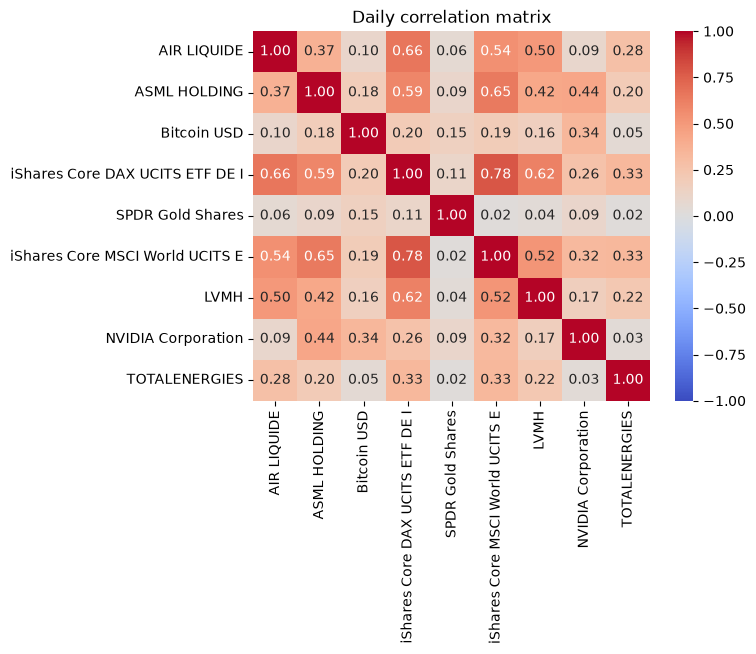

In [5]:
sns.heatmap(daily_corr_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Daily correlation matrix")
plt.show()

### Interpretation
A high correlation does not come from belonging to an index. It comes from common factors: same sector, same sensitivity to interest rates, same region. It is also a way to detect indirect correlations between stakeholders.

## Weekly correlation matrix
The assets are not listed at the same time: European markets close around 17:30 (Paris time), US markets around 22:00, and Bitcoin trades 24/7.
An event that happens after the European close shows up on different days depending on the asset, which lowers the daily correlation between markets.
Using weekly returns (last price of each week) reduces this effect, at the cost of fewer data points.

In [6]:
weekly_prices = df.resample("W").last()


weekly_returns = compute_returns(weekly_prices)

weekly_corr_matrix = weekly_returns.corr()
weekly_corr_display = weekly_corr_matrix.rename(index=name_by_ticker, columns=name_by_ticker)
weekly_corr_display


,AIR LIQUIDE,ASML HOLDING,Bitcoin USD,iShares Core DAX UCITS ETF DE I,SPDR Gold Shares,iShares Core MSCI World UCITS E,LVMH,NVIDIA Corporation,TOTALENERGIES
AIR LIQUIDE,1.000000,0.434597,0.100508,0.685418,0.163838,0.552903,0.521548,0.248768,0.297731
ASML HOLDING,0.434597,1.000000,0.172848,0.596798,0.132308,0.682788,0.538016,0.568425,0.203590
Bitcoin USD,0.100508,0.172848,1.000000,0.166332,0.129774,0.263571,0.147187,0.286775,-0.012722
iShares Core DAX UCITS ETF DE I,0.685418,0.596798,0.166332,1.000000,0.216312,0.763769,0.670494,0.351995,0.313908
SPDR Gold Shares,0.163838,0.132308,0.129774,0.216312,1.000000,0.195590,0.136627,0.071159,0.073061
iShares Core MSCI World UCITS E,0.552903,0.682788,0.263571,0.763769,0.195590,1.000000,0.566844,0.603150,0.275573
LVMH,0.521548,0.538016,0.147187,0.670494,0.136627,0.566844,1.000000,0.285189,0.129420
NVIDIA Corporation,0.248768,0.568425,0.286775,0.351995,0.071159,0.603150,0.285189,1.000000,0.031089
TOTALENERGIES,0.297731,0.203590,-0.012722,0.313908,0.073061,0.275573,0.129420,0.031089,1.000000


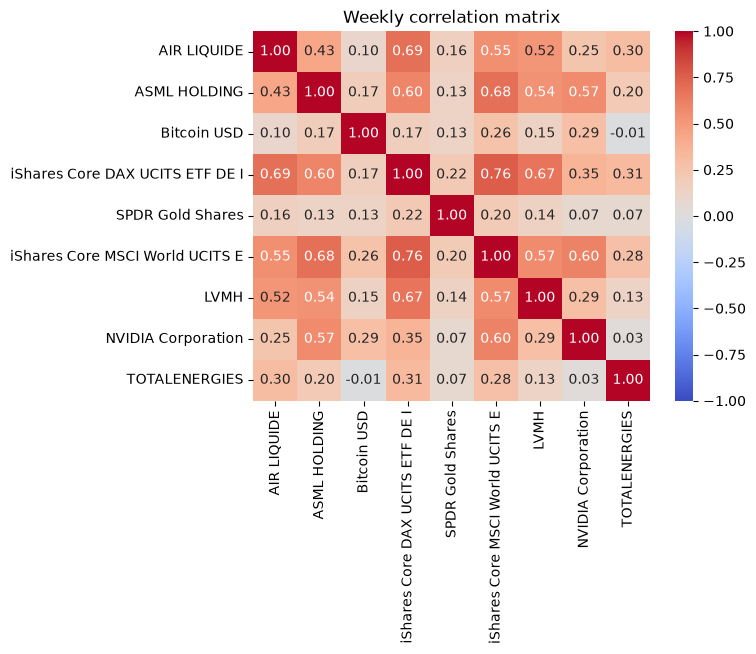

In [7]:
sns.heatmap(weekly_corr_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Weekly correlation matrix")
plt.show()

## Daily vs weekly correlation
The heatmap below shows, for each pair, the weekly correlation minus the daily correlation.
- **Red:** the pair is more correlated with weekly returns
- **Blue:** the pair is less correlated with weekly returns

### Interpretation
_To do_

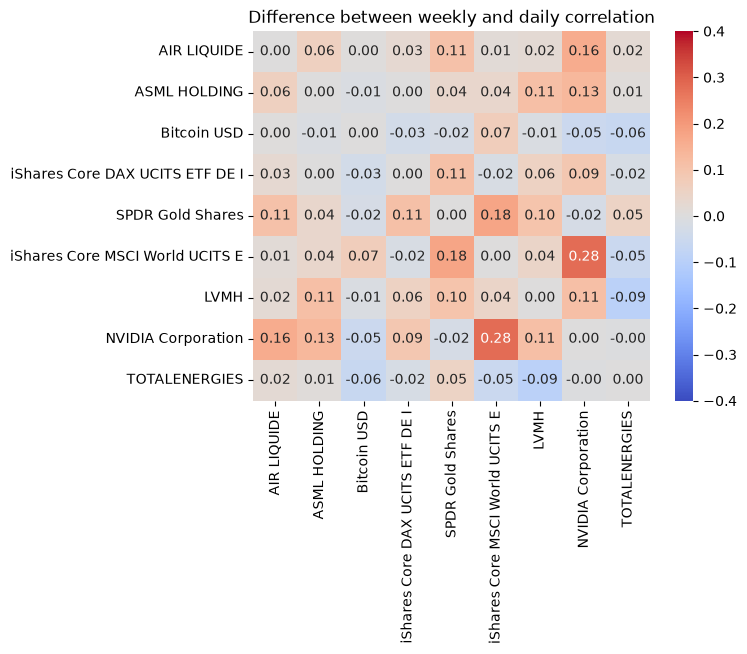

In [8]:
corr_diff = weekly_corr_matrix - daily_corr_matrix
corr_diff_display = corr_diff.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(corr_diff_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.4, vmax=0.4)
plt.title("Difference between weekly and daily correlation")
plt.show()

## Rolling correlation

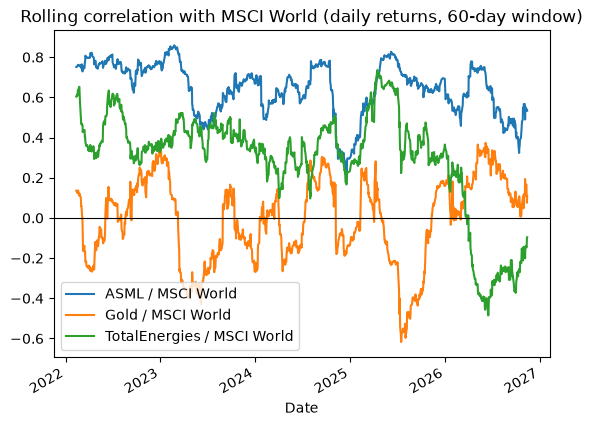

In [9]:
rolling_corr_asml_iwda = daily_returns["ASML.AS"].rolling(60).corr(daily_returns["IWDA.AS"])
rolling_corr_gld_iwda = daily_returns["GLD"].rolling(60).corr(daily_returns["IWDA.AS"])
rolling_corr_tte_iwda = daily_returns["TTE.PA"].rolling(60).corr(daily_returns["IWDA.AS"])

rolling_corr_asml_iwda.plot(title="Rolling correlation with MSCI World (daily returns, 60-day window)", grid=True, label="ASML / MSCI World")
rolling_corr_gld_iwda.plot(label="Gold / MSCI World")
rolling_corr_tte_iwda.plot(label="TotalEnergies / MSCI World")

plt.axhline(0, color="black", linewidth=0.8)
plt.legend()
plt.show()

## Correlation during market stress

In [10]:
stress_threshold_iwda = daily_returns["IWDA.AS"].quantile(0.05)
stress_returns = daily_returns[daily_returns["IWDA.AS"] <= stress_threshold_iwda]

print(f"Stress threshold (5% worst days of MSCI World): {stress_threshold_iwda:.2%}")
print(f"Number of stress days: {len(stress_returns)}")

Stress threshold (5% worst days of MSCI World): -1.58%
Number of stress days: 62


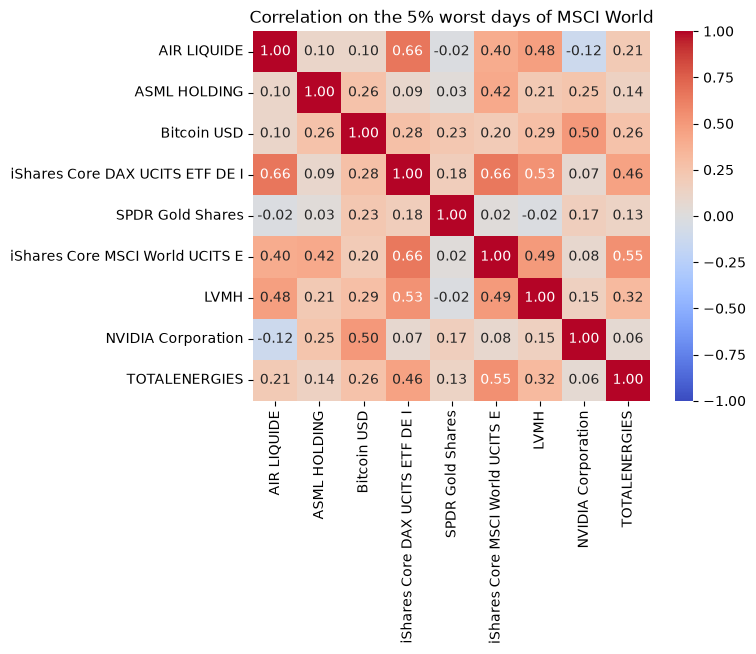

In [11]:
stress_corr_matrix = stress_returns.corr()
stress_corr_display = stress_corr_matrix.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(stress_corr_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation on the 5% worst days of MSCI World")
plt.show()

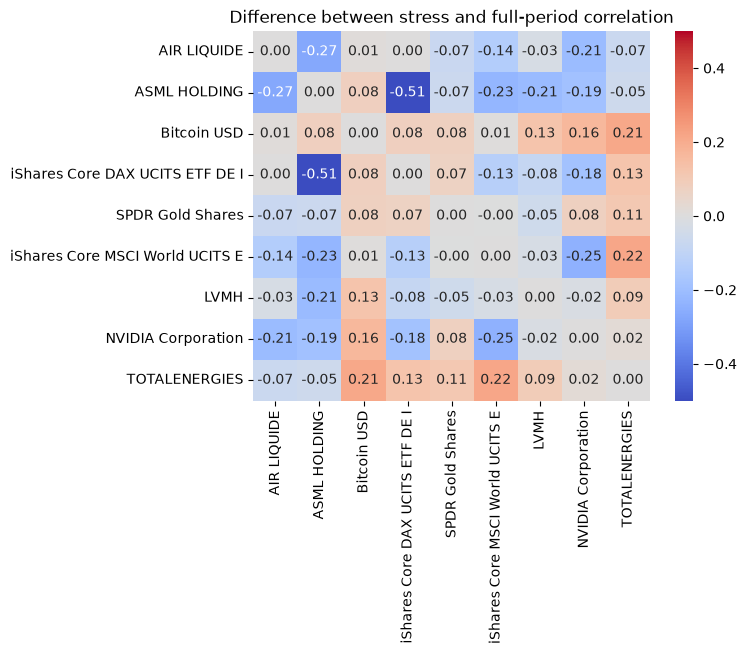

In [12]:
stress_corr_diff = stress_corr_matrix - daily_corr_matrix
stress_corr_diff_display = stress_corr_diff.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(stress_corr_diff_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=0.5)
plt.title("Difference between stress and full-period correlation")
plt.show()

### Comparison with the best days
Keeping only the extreme days of the MSCI World reduces its variation, which mechanically lowers the correlations (selection bias).
To remove this effect, the worst days are compared with the 5% best days ("rally" days), which suffer from the same bias.

In [13]:
rally_threshold_iwda = daily_returns["IWDA.AS"].quantile(0.95)
rally_returns = daily_returns[daily_returns["IWDA.AS"] >= rally_threshold_iwda]

print(f"Rally threshold (5% best days of MSCI World): {rally_threshold_iwda:.2%}")
print(f"Number of rally days: {len(rally_returns)}")

Rally threshold (5% best days of MSCI World): 1.67%
Number of rally days: 62


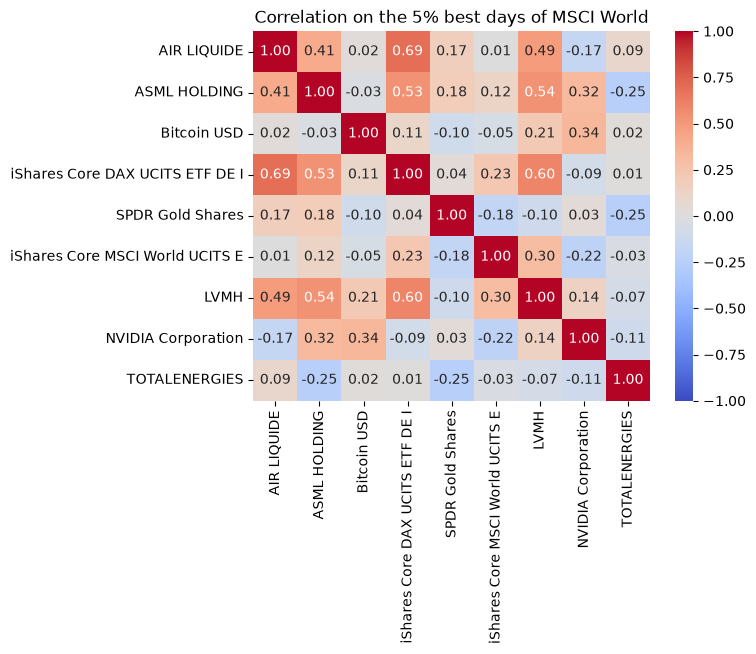

In [14]:
rally_corr_matrix = rally_returns.corr()
rally_corr_display = rally_corr_matrix.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(rally_corr_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation on the 5% best days of MSCI World")
plt.show()

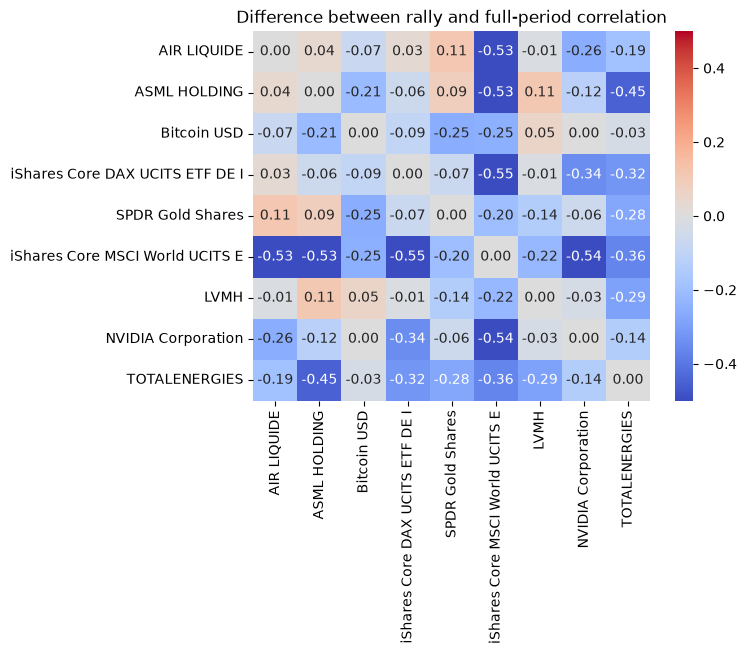

In [15]:
rally_corr_diff = rally_corr_matrix - daily_corr_matrix
rally_corr_diff_display = rally_corr_diff.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(rally_corr_diff_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=0.5)
plt.title("Difference between rally and full-period correlation")
plt.show()

### Worst days vs best days
For each pair, correlation on the worst days minus correlation on the best days.
- **Red:** the assets are more correlated when the market falls than when it rises
- **Blue:** the opposite

### Interpretation
_To do_

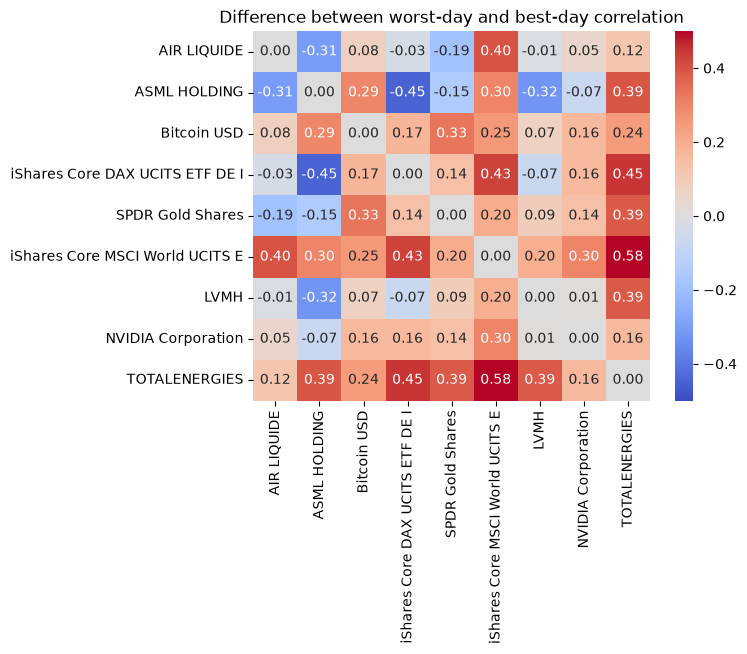

In [16]:
stress_vs_rally_diff = stress_corr_matrix - rally_corr_matrix
stress_vs_rally_diff_display = stress_vs_rally_diff.rename(index=name_by_ticker, columns=name_by_ticker)

sns.heatmap(stress_vs_rally_diff_display, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=0.5)
plt.title("Difference between worst-day and best-day correlation")
plt.show()

## Conclusion
_To do_